# Beyond diffusion: Flow Matching, step by step 🌊
### Learn a *velocity field* that carries noise onto data - from scratch, on a laptop CPU

> **Scope note.** The notebook is named after the talk title *"Beyond Diffusion: Flow Matching for Generative AI"*; I could not watch the video, so this is **not** a transcript or a summary of it. It teaches flow matching from first principles, using the original papers, and **every claim is tested in a cell** (look for `PASS` lines and the table at the end).

**Papers used**
- Lipman et al., *Flow Matching for Generative Modeling* (ICLR 2023, [arXiv 2210.02747](https://arxiv.org/abs/2210.02747)) - the CFM loss, Eq. (9) and (23).
- Liu et al., *Flow Straight and Fast: Rectified Flow* ([arXiv 2209.03003](https://arxiv.org/abs/2209.03003)) - straight paths and *reflow*.
- (also relevant: Albergo & Vanden-Eijnden, *Building Normalizing Flows with Stochastic Interpolants*, [arXiv 2209.15571](https://arxiv.org/abs/2209.15571))

| step | what you will do |
|---|---|
| 1 | state the problem: move a noise cloud onto the data |
| 2 | the idea: a velocity field and an ODE (and what changes versus diffusion) |
| 3 | build the straight path and its target velocity - and test it |
| 4 | *why regressing on a per-pair target works*: an exact 1-D check with a closed-form answer |
| 5 | train the 2-D model (a few seconds) |
| 6 | sample with an ODE solver; **how many steps do you need?** |
| 7 | flow vs a diffusion-style path, measured |
| 8 | straight paths and *reflow* -> one-step generation |
| 9 | conditioning and classifier-free guidance |
| 10 | where this appears in this repo (discrete flow matching for text) and in driving policies |

In [1]:
import math, os, time, io
from pathlib import Path
import numpy as np, torch, torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from IPython.display import Image, display

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
ASSETS = Path("../../assets/flow_matching").resolve()      # GIFs and paper figures live here
ASSETS.mkdir(parents=True, exist_ok=True)
NOISE_C, DATA_C, FLOW_C, COS_C = "#7b8794", "#d9480f", "#1c7ed6", "#9c36b5"

CHECKS = []
def check(name, ok, detail=""):
    """Record and print one verifier line (the table at the end re-reads CHECKS)."""
    CHECKS.append((name, bool(ok), detail))
    print(("PASS" if ok else "FAIL"), "-", name, ("| " + detail) if detail else "")
print("torch", torch.__version__, "| CPU only is fine")

torch 2.14.1 | CPU only is fine


## Step 1 - The problem: turn noise into data

A generative model must produce *new* samples that look like the training data. Flow matching (like diffusion) does it by **transport**: start from something trivially easy to sample, **noise** $x_0 \sim \mathcal N(0, I)$, and *move every point* until the cloud looks like the data $x_1 \sim q$.

We use the classic **two moons** toy set. It is small enough to see every point, yet has the feature that makes generation non-trivial: two separate curved modes.

data  mean [ 0.01 -0.01]  std [1.76 0.98]
noise mean [-0.01 -0.01]  std [0.98 0.99]


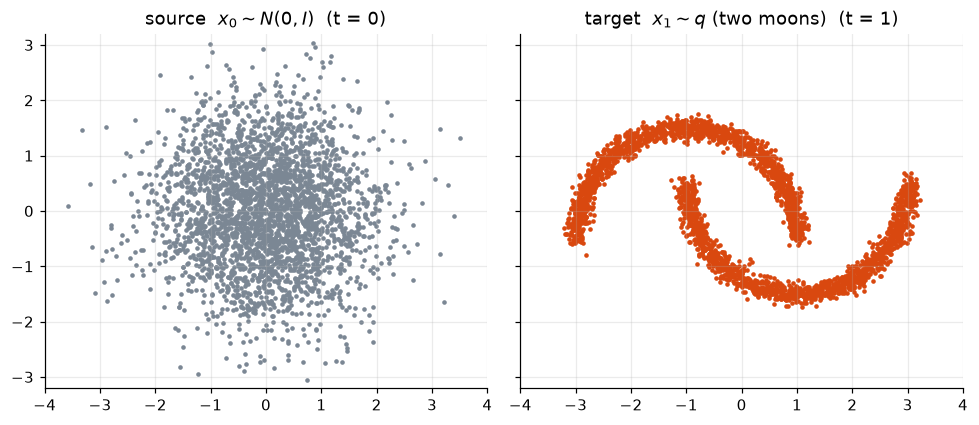

In [2]:
def moons(n, noise=0.05, gen=None):
    """Two interleaving half-moons, centred and scaled to roughly unit spread. Returns (points, class 0/1)."""
    k = n // 2
    a = torch.rand(k, generator=gen) * math.pi
    b = torch.rand(n - k, generator=gen) * math.pi
    upper = torch.stack([torch.cos(a), torch.sin(a)], 1)
    lower = torch.stack([1 - torch.cos(b), 0.5 - torch.sin(b)], 1)
    x = torch.cat([upper, lower]) + noise * torch.randn(n, 2, generator=gen)
    y = torch.cat([torch.zeros(k), torch.ones(n - k)]).long()
    return (x - torch.tensor([0.5, 0.25])) * 2.0, y

g = torch.Generator().manual_seed(123)
data, labels = moons(3000, gen=g)
noise = torch.randn(3000, 2, generator=g)
print("data  mean", data.mean(0).numpy().round(2), " std", data.std(0).numpy().round(2))
print("noise mean", noise.mean(0).numpy().round(2), " std", noise.std(0).numpy().round(2))

fig, ax = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
ax[0].scatter(*noise.T, s=4, c=NOISE_C); ax[0].set_title("source  $x_0 \\sim N(0, I)$  (t = 0)")
ax[1].scatter(*data.T, s=4, c=DATA_C);  ax[1].set_title("target  $x_1 \\sim q$ (two moons)  (t = 1)")
for a in ax: a.set_aspect("equal"); a.set_xlim(-4, 4); a.set_ylim(-3.2, 3.2)
plt.tight_layout(); plt.show()

## Step 2 - The idea: a velocity field and an ODE

Think of every noise point as a particle. We want a rule that says, for a particle at position $x$ at time $t \in [0, 1]$, **which way to move and how fast**:

$$\frac{dx}{dt} = v_\theta(x, t), \qquad x(0) = x_0 \sim \mathcal N(0, I).$$

This is an ordinary differential equation (a *continuous normalizing flow*). If $v_\theta$ is right, integrating it from $t=0$ to $t=1$ drops the noise cloud on the data. **Generation = solving an ODE**; the network only has to output a 2-D arrow.

*How is this different from diffusion?* Diffusion trains a network to undo gradual noising (predict the noise or the score), and the paths it implies are **curved** and need many small steps. Flow matching says: *choose the path yourself* - the simplest one, a straight line - and regress the velocity along it. Lipman et al. state the contrast in their Fig. 2:

![Lipman et al. Fig. 2](../../assets/flow_matching/lipman_fig2_diffusion_vs_ot.png)

**Lipman et al. (2023), Fig. 2 (PDF p. 6):** "Compared to the diffusion path's conditional score function, the OT path's conditional vector field has constant direction in time and is arguably simpler to fit with a parametric model."

*What to look for:* on the right (the straight "OT" path) the arrows keep pointing at the same place for all $t$; on the left (diffusion) the picture changes with time.

## Step 3 - The straight path and its target velocity

Pick **one noise point $x_0$ and one data point $x_1$** and connect them with a straight line, parametrised by time:

$$x_t = (1-t)\,x_0 + t\,x_1, \qquad \frac{dx_t}{dt} = x_1 - x_0 =: u .$$

So the **target velocity along this path is a constant, $u = x_1 - x_0$** - the arrow from noise to data. (Lipman et al. Eq. (22)-(23) with $\sigma_{\min}\to 0$.)

Verifier: the path hits both endpoints, and a finite-difference derivative equals $u$.

PASS - path starts at the noise point (t=0) 
PASS - path ends at the data point (t=1) 
PASS - finite-difference d x_t / dt equals x1 - x0 | max err 2.1e-04


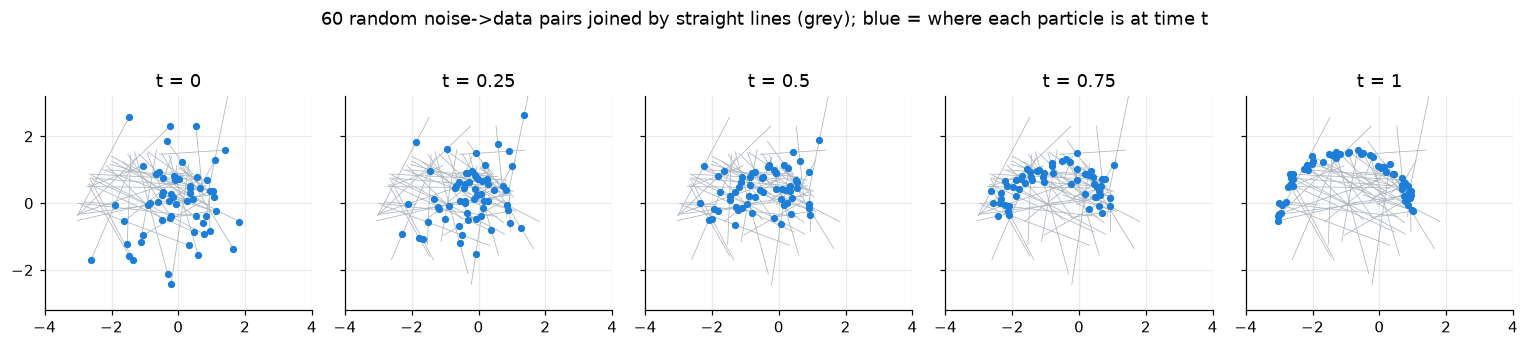

In [3]:
def linear_path(x0, x1, t):
    """Straight interpolant between noise x0 (t=0) and data x1 (t=1), and its velocity (a constant)."""
    xt = (1 - t) * x0 + t * x1
    ut = x1 - x0
    return xt, ut

x0 = torch.randn(1000, 2); x1, _ = moons(1000, gen=g)
t = torch.rand(1000, 1)
xt, ut = linear_path(x0, x1, t)
z, o = torch.zeros(1000, 1), torch.ones(1000, 1)
check("path starts at the noise point (t=0)", torch.allclose(linear_path(x0, x1, z)[0], x0))
check("path ends at the data point (t=1)", torch.allclose(linear_path(x0, x1, o)[0], x1))
h = 1e-3
fd = (linear_path(x0, x1, (t + h).clamp(max=1.2))[0] - linear_path(x0, x1, t - h)[0]) / (2 * h)
check("finite-difference d x_t / dt equals x1 - x0", torch.allclose(fd, ut, atol=1e-3), f"max err {(fd-ut).abs().max():.1e}")

# draw 60 random (noise, data) pairs and where they are at t = 0, .25, .5, .75, 1
fig, axs = plt.subplots(1, 5, figsize=(14, 3), sharex=True, sharey=True)
idx = slice(0, 60)
for a, tt in zip(axs, (0, .25, .5, .75, 1)):
    p = (1 - tt) * x0[idx] + tt * x1[idx]
    a.plot([x0[idx, 0].numpy(), x1[idx, 0].numpy()], [x0[idx, 1].numpy(), x1[idx, 1].numpy()], c="#adb5bd", lw=.5, zorder=1)
    a.scatter(*p.T, s=14, c=FLOW_C, zorder=2); a.set_title(f"t = {tt}"); a.set_aspect("equal")
    a.set_xlim(-4, 4); a.set_ylim(-3.2, 3.2)
plt.suptitle("60 random noise->data pairs joined by straight lines (grey); blue = where each particle is at time t", y=1.03)
plt.tight_layout(); plt.show()

Notice the grey lines **cross each other**. That is fine for a pairing, but a *single* velocity field $v(x,t)$ can only give **one** arrow at each point - so where lines cross, the network will learn their **average**. That averaging is exactly the subtle part, and it is what Step 4 checks.

## Step 4 - Why regressing on a per-pair target works (an exact check)

The training loss is the **Conditional Flow Matching** loss (Lipman et al., Eq. (9)), here with the straight path:

$$\boxed{\;\mathcal L(\theta) = \mathbb E_{t\sim U[0,1],\;x_0\sim\mathcal N,\;x_1\sim q}\;\big\|\,v_\theta(x_t,t) - (x_1 - x_0)\,\big\|^2\;}$$

Lipman et al. (PDF p. 5): *"we consider the Conditional Flow Matching (CFM) objective $\mathcal L_{CFM}(\theta)=\mathbb E_{t,q(x_1),p_t(x|x_1)}\|v_t(x)-u_t(x|x_1)\|^2$ (9) ... which surprisingly will result in the same optima as the original objective."*

Why? A squared-error regression is minimised by the **conditional mean**, so the optimum is

$$v^\*(x,t) = \mathbb E\big[\,x_1 - x_0 \;\big|\; x_t = x\,\big]$$

- the *average* of all pair-velocities passing through $(x,t)$. That average is exactly the *marginal* velocity field that transports the whole noise distribution onto the whole data distribution (Lipman et al. Eq. (8)).

**A closed form to test it against.** Take 1-D data with just two values, $x_1\in\{-1,+1\}$ (equal probability), and $x_0\sim\mathcal N(0,1)$. Given $x_t=x$, Bayes gives $P(x_1=+1\mid x)=\sigma\!\big(2tx/(1-t)^2\big)$, so $\mathbb E[x_1\mid x]=\tanh\!\big(tx/(1-t)^2\big)$, and since $x_0=(x-tx_1)/(1-t)$:

$$v^\*(x,t)=\frac{\tanh\!\big(\tfrac{t\,x}{(1-t)^2}\big)-x}{1-t}.$$

Two independent tests: (a) bin Monte-Carlo pair velocities and compare with $v^\*$; (b) train a small network with the loss above and compare it with $v^\*$.

PASS - binned pair-velocities match the closed form at t=0.3 | max |error| = 0.022
PASS - binned pair-velocities match the closed form at t=0.6 | max |error| = 0.047


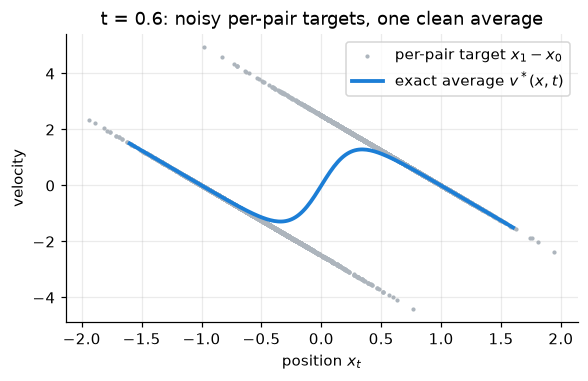

In [4]:
def v_star(x, t):
    """Exact marginal velocity for data {-1,+1} (equal prob.) and N(0,1) noise, straight path."""
    return (torch.tanh(t * x / (1 - t) ** 2) - x) / (1 - t)

# (a) Monte-Carlo: average the per-pair target x1 - x0 inside bins of x_t at fixed t
torch.manual_seed(1)
N = 2_000_000
x0_ = torch.randn(N); x1_ = (torch.randint(0, 2, (N,)) * 2 - 1).float()
rows = []
for tt in (0.3, 0.6):
    xt_ = (1 - tt) * x0_ + tt * x1_; u_ = x1_ - x0_
    edges = torch.linspace(-1.6, 1.6, 17); centres = (edges[:-1] + edges[1:]) / 2
    est = torch.stack([u_[(xt_ >= lo) & (xt_ < hi)].mean() for lo, hi in zip(edges[:-1], edges[1:])])
    exact = v_star(centres, torch.tensor(tt))
    err = (est - exact).abs().max().item(); rows.append(err)
    check(f"binned pair-velocities match the closed form at t={tt}", err < 0.05, f"max |error| = {err:.3f}")

fig, ax = plt.subplots(figsize=(6, 3.4))
tt = 0.6; xt_ = (1 - tt) * x0_ + tt * x1_; u_ = x1_ - x0_
ax.scatter(xt_[:4000], u_[:4000], s=3, c="#adb5bd", label="per-pair target $x_1-x_0$")
xs = torch.linspace(-1.6, 1.6, 200); ax.plot(xs, v_star(xs, torch.tensor(tt)), c=FLOW_C, lw=2.5, label="exact average $v^*(x,t)$")
ax.set_xlabel("position $x_t$"); ax.set_ylabel("velocity"); ax.set_title("t = 0.6: noisy per-pair targets, one clean average"); ax.legend(); plt.show()

trained in 11.9s, final CFM loss 1.044


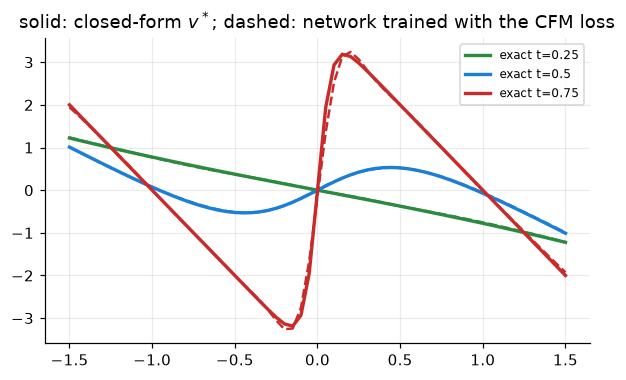

{0.25: 0.01, 0.5: 0.009, 0.75: 0.047}
PASS - the CFM-trained network recovers the exact marginal velocity | mean |error| per t: 0.25: 0.010, 0.5: 0.009, 0.75: 0.047  (velocities span about +-2; t=0.75 is hardest because v* steepens near t=1)


In [5]:
class VelocityNet(nn.Module):
    """MLP v_theta(x, t[, class]) -> velocity. Time enters as t plus a few Fourier features; classes get an embedding
    (index n_cls is the 'no label' token used for classifier-free guidance)."""
    def __init__(self, dim=2, hidden=128, layers=3, n_cls=0):
        super().__init__()
        self.n_cls = n_cls
        self.register_buffer("freqs", 2 * math.pi * torch.arange(1, 5).float())
        self.emb = nn.Embedding(n_cls + 1, 16) if n_cls else None
        d_in = dim + 1 + 8 + (16 if n_cls else 0)
        mods = [nn.Linear(d_in, hidden), nn.SiLU()]
        for _ in range(layers - 1): mods += [nn.Linear(hidden, hidden), nn.SiLU()]
        self.net = nn.Sequential(*mods, nn.Linear(hidden, dim))

    def forward(self, x, t, y=None):
        t = t.reshape(-1, 1).expand(x.shape[0], 1)
        feats = [x, t, torch.sin(t * self.freqs), torch.cos(t * self.freqs)]
        if self.emb is not None:
            feats.append(self.emb(y if y is not None else torch.full((x.shape[0],), self.n_cls)))
        return self.net(torch.cat(feats, 1))

# (b) train on the 1-D two-point problem with the CFM loss
torch.manual_seed(2)
net1d = VelocityNet(dim=1, hidden=128, layers=3)
opt = torch.optim.Adam(net1d.parameters(), lr=2e-3)
sched1 = torch.optim.lr_scheduler.CosineAnnealingLR(opt, 10000)
t0 = time.time()
for step in range(10000):
    x0b = torch.randn(2048, 1); x1b = (torch.randint(0, 2, (2048, 1)) * 2 - 1).float()
    tb = torch.rand(2048, 1) * 0.97                       # stay away from t -> 1, where v* is steep
    xtb, ub = linear_path(x0b, x1b, tb)
    loss = ((net1d(xtb, tb) - ub) ** 2).mean()
    opt.zero_grad(); loss.backward(); opt.step(); sched1.step()
print(f"trained in {time.time()-t0:.1f}s, final CFM loss {loss.item():.3f}")

grid_x = torch.linspace(-1.5, 1.5, 61).unsqueeze(1)
errs = {}
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for tt, c in zip((0.25, 0.5, 0.75), ("#2b8a3e", FLOW_C, "#c92a2a")):
    pred = net1d(grid_x, torch.full((61, 1), tt)).detach().squeeze()
    ex = v_star(grid_x.squeeze(), torch.tensor(tt))
    errs[tt] = (pred - ex).abs().mean().item()
    ax.plot(grid_x, ex, c=c, lw=2.2, label=f"exact t={tt}"); ax.plot(grid_x, pred, c=c, ls="--", lw=1.6)
ax.set_title("solid: closed-form $v^*$; dashed: network trained with the CFM loss"); ax.legend(fontsize=8); plt.show()
print({k: round(v, 3) for k, v in errs.items()})
check("the CFM-trained network recovers the exact marginal velocity", max(errs.values()) < 0.1,
      f"mean |error| per t: " + ", ".join(f"{k}: {v:.3f}" for k, v in errs.items()) + "  (velocities span about +-2; t=0.75 is hardest because v* steepens near t=1)")

**Read the plot.** The network never saw $v^*$; it only saw noisy per-pair arrows - and it learned their *average*, i.e. the true transport field. That is why such a simple regression is enough, and why training needs **no ODE solver** ("simulation-free").

## Step 5 - Train the 2-D model
Same loss, same network class, now on two moons. Each step: sample noise $x_0$, data $x_1$, time $t$; build $x_t$ and target $u$; regress.

[linear] 4000 steps in 3s, loss 2.475 -> 1.879


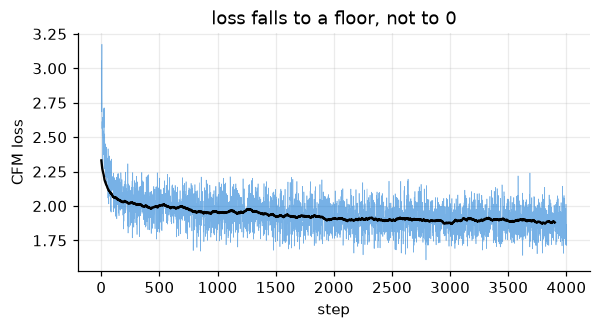

In [6]:
PATHS = {
    # name: fn(x0, x1, t) -> (x_t, target velocity); t = 0 is noise, t = 1 is data for both
    "linear": linear_path,
    "cosine": lambda x0, x1, t: (torch.sin(math.pi / 2 * t) * x1 + torch.cos(math.pi / 2 * t) * x0,
                                 math.pi / 2 * (torch.cos(math.pi / 2 * t) * x1 - torch.sin(math.pi / 2 * t) * x0)),
}

def train_fm(path="linear", steps=4000, batch=512, lr=2e-3, seed=0, cond=False, pair_fn=None, init=None, p_uncond=0.15, log=True):
    """Train a VelocityNet with the CFM loss. pair_fn(batch) -> (x0, x1, y) overrides the default (noise, moons) pairs."""
    torch.manual_seed(seed)
    model = VelocityNet(n_cls=2 if cond else 0)
    if init is not None: model.load_state_dict(init.state_dict())
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    hist, t0 = [], time.time()
    for step in range(steps):
        if pair_fn is None:
            x1, y = moons(batch); x0 = torch.randn(batch, 2)
        else:
            x0, x1, y = pair_fn(batch)
        t = torch.rand(batch, 1)
        xt, ut = PATHS[path](x0, x1, t)
        if cond:
            y = torch.where(torch.rand(batch) < p_uncond, torch.full_like(y, 2), y)   # label dropout -> unconditional too
        loss = ((model(xt, t, y if cond else None) - ut) ** 2).mean()
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 2.0); opt.step(); sched.step()
        hist.append(loss.item())
    if log: print(f"[{path}{' cond' if cond else ''}] {steps} steps in {time.time()-t0:.0f}s, loss {np.mean(hist[:50]):.3f} -> {np.mean(hist[-200:]):.3f}")
    return model, hist

flow, flow_hist = train_fm("linear")
plt.figure(figsize=(6, 2.8)); plt.plot(flow_hist, c=FLOW_C, lw=.4, alpha=.6); plt.plot(np.convolve(flow_hist, np.ones(100)/100, "valid"), c="k")
plt.xlabel("step"); plt.ylabel("CFM loss"); plt.title("loss falls to a floor, not to 0"); plt.show()

*Why the loss does not reach 0:* the target $x_1-x_0$ depends on the *pair*, but the network only sees the *position*. Crossing lines (Step 3) make the per-pair target unpredictable, so the best possible loss is the irreducible variance around the average. A flat floor is therefore healthy, not a bug.

## Step 6 - Sampling = solving the ODE (and how many steps you need)

To generate: draw $x_0\sim\mathcal N(0,I)$ and integrate $\dot x = v_\theta(x,t)$ from $0$ to $1$.

- **Euler** with $N$ steps: $x \leftarrow x + h\,v_\theta(x,t)$, $h=1/N$ - one network call per step.
- **Heun** (2nd order): average the slope at the start and at the predicted end - two calls per step, but far more accurate.

The only knob is the number of function evaluations (**NFE**). We score with the **sliced Wasserstein distance** (SW) to fresh data (lower is better); the floor is the SW between two *independent* samples of the data itself.

SW floor (data vs data) = 0.054    SW of raw noise vs data = 0.589


N=   1  Euler SW 1.327 (NFE    1)   Heun SW 0.848 (NFE    2)
N=   2  Euler SW 0.665 (NFE    2)   Heun SW 0.160 (NFE    4)
N=   3  Euler SW 0.445 (NFE    3)   Heun SW 0.078 (NFE    6)
N=   4  Euler SW 0.319 (NFE    4)   Heun SW 0.045 (NFE    8)
N=   8  Euler SW 0.148 (NFE    8)   Heun SW 0.050 (NFE   16)
N=  16  Euler SW 0.067 (NFE   16)   Heun SW 0.056 (NFE   32)
N=  32  Euler SW 0.042 (NFE   32)   Heun SW 0.055 (NFE   64)
N=  64  Euler SW 0.044 (NFE   64)   Heun SW 0.055 (NFE  128)
N= 128  Euler SW 0.049 (NFE  128)   Heun SW 0.055 (NFE  256)


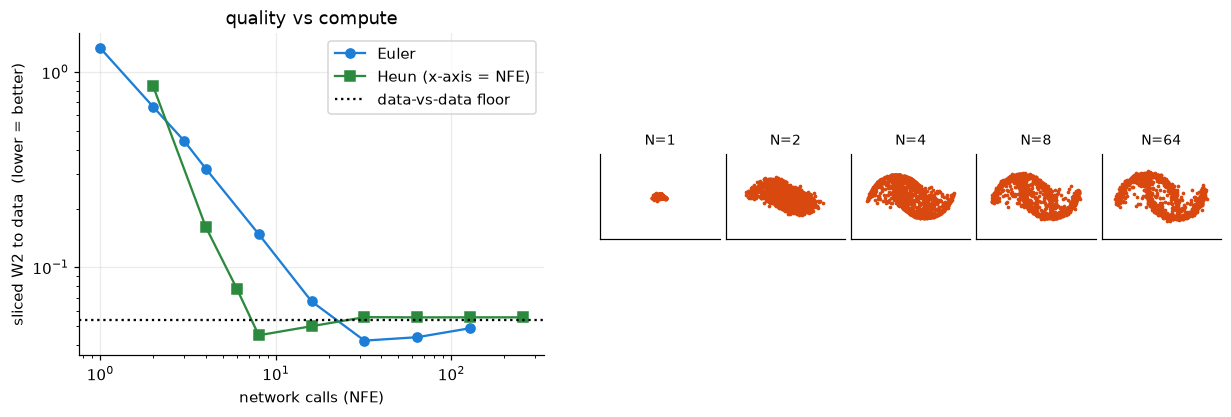

PASS - more Euler steps -> better samples (N=1 is much worse than N=64) | SW 1.327 -> 0.044
PASS - with enough steps the samples reach the data-vs-data floor (within 0.05) | 0.049 vs floor 0.054
PASS - Heun beats Euler at the same NFE (8 calls) | Heun 0.045 vs Euler 0.148


In [7]:
@torch.no_grad()
def velocity(model, x, t, y=None, w=0.0):
    """Model velocity; with labels, classifier-free guidance v_u + w (v_c - v_u)  (w=1: plain conditional, w=0: unconditional)."""
    if y is None: return model(x, t)
    v_c = model(x, t, y)
    v_u = model(x, t, torch.full_like(y, model.n_cls))
    return v_u + w * (v_c - v_u)

@torch.no_grad()
def sample(model, x0, steps=64, method="euler", y=None, w=1.0, return_traj=False):
    """Integrate the learned ODE from t=0 to 1. method: 'euler' (1 call/step) or 'heun' (2 calls/step)."""
    ts = torch.linspace(0, 1, steps + 1)
    x, traj = x0.clone(), [x0.clone()]
    f = lambda x, t: velocity(model, x, t.expand(x.shape[0], 1), y, w)
    for i in range(steps):
        t0_, t1_ = ts[i].reshape(1, 1), ts[i + 1].reshape(1, 1); h = (t1_ - t0_)
        if method == "euler":
            x = x + h * f(x, t0_)
        else:
            k1 = f(x, t0_); k2 = f(x + h * k1, t1_); x = x + h * (k1 + k2) / 2
        traj.append(x.clone())
    return (x, torch.stack(traj)) if return_traj else x

_dirs = torch.nn.functional.normalize(torch.randn(256, 2, generator=torch.Generator().manual_seed(7)), dim=1)
def sliced_w2(a, b):
    """Sliced Wasserstein-2 distance between two equal-size 2-D point sets (256 fixed directions)."""
    pa, pb = (a @ _dirs.T).sort(0).values, (b @ _dirs.T).sort(0).values
    return ((pa - pb) ** 2).mean().sqrt().item()

ref_a, _ = moons(4000, gen=torch.Generator().manual_seed(11)); ref_b, _ = moons(4000, gen=torch.Generator().manual_seed(12))
FLOOR = sliced_w2(ref_a, ref_b)
noise_sw = sliced_w2(torch.randn(4000, 2, generator=torch.Generator().manual_seed(13)), ref_a)
print(f"SW floor (data vs data) = {FLOOR:.3f}    SW of raw noise vs data = {noise_sw:.3f}")

z0 = torch.randn(4000, 2, generator=torch.Generator().manual_seed(21))
Ns = [1, 2, 3, 4, 8, 16, 32, 64, 128]
sw_euler = [sliced_w2(sample(flow, z0, n, "euler"), ref_a) for n in Ns]
sw_heun  = [sliced_w2(sample(flow, z0, n, "heun"), ref_a) for n in Ns]
for n, a, b in zip(Ns, sw_euler, sw_heun): print(f"N={n:4d}  Euler SW {a:.3f} (NFE {n:4d})   Heun SW {b:.3f} (NFE {2*n:4d})")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].loglog(Ns, sw_euler, "o-", c=FLOW_C, label="Euler"); ax[0].loglog([2*n for n in Ns], sw_heun, "s-", c="#2b8a3e", label="Heun (x-axis = NFE)")
ax[0].axhline(FLOOR, c="k", ls=":", label="data-vs-data floor"); ax[0].set_xlabel("network calls (NFE)"); ax[0].set_ylabel("sliced W2 to data  (lower = better)"); ax[0].legend()
ax[0].set_title("quality vs compute")
ax[1].axis("off")
sub = fig.add_gridspec(1, 5, left=0.52, right=0.99, wspace=.05, bottom=.1, top=.88)
for j, n in enumerate((1, 2, 4, 8, 64)):
    a = fig.add_subplot(sub[0, j]); s = sample(flow, z0[:1500], n, "euler")
    a.scatter(*s.T, s=2, c=DATA_C); a.set_title(f"N={n}", fontsize=9); a.set_xlim(-4.2, 4.2); a.set_ylim(-3, 3); a.set_xticks([]); a.set_yticks([]); a.set_aspect("equal")
plt.show()
check("more Euler steps -> better samples (N=1 is much worse than N=64)", sw_euler[0] > 3 * sw_euler[Ns.index(64)], f"SW {sw_euler[0]:.3f} -> {sw_euler[Ns.index(64)]:.3f}")
check("with enough steps the samples reach the data-vs-data floor (within 0.05)", sw_euler[Ns.index(128)] < FLOOR + 0.05, f"{sw_euler[Ns.index(128)]:.3f} vs floor {FLOOR:.3f}")
check("Heun beats Euler at the same NFE (8 calls)", sw_heun[Ns.index(4)] < sw_euler[Ns.index(8)], f"Heun {sw_heun[Ns.index(4)]:.3f} vs Euler {sw_euler[Ns.index(8)]:.3f}")

**Read the plots.** One Euler step ($N=1$) puts every point on the *average* arrow, giving a blob in the middle; each doubling of steps bends the cloud closer to the moons; by $N\!\approx\!32$-$64$ it is indistinguishable from real data. The second-order solver reaches the same quality with fewer calls.

### The animation: noise flowing onto the data
Each dot is one noise sample; we advance the ODE and draw the cloud (and 40 trails) at every step.

In [8]:
def fig_to_pil(fig):
    buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=80); buf.seek(0)
    return PILImage.open(buf).convert("P", palette=PILImage.ADAPTIVE)

@torch.no_grad()
def flow_particles_gif(model, path_out, n=1200, steps=48, seed=5):
    z = torch.randn(n, 2, generator=torch.Generator().manual_seed(seed))
    _, traj = sample(model, z, steps, "heun", return_traj=True)       # (steps+1, n, 2)
    frames = []
    show = list(range(0, steps + 1, 2)) + [steps] * 6
    for k in show:
        fig, ax = plt.subplots(figsize=(5.2, 4.4))
        for j in range(40): ax.plot(traj[:k + 1, j, 0], traj[:k + 1, j, 1], c="#adb5bd", lw=.7, zorder=1)
        ax.scatter(*traj[k].T, s=5, c=DATA_C if k == steps else FLOW_C, zorder=2)
        ax.set_xlim(-3.8, 3.8); ax.set_ylim(-3, 3); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        t = k / steps
        ax.set_title(f"flow matching: noise -> two moons    t = {t:.2f}", fontsize=10)
        ax.add_patch(plt.Rectangle((-3.8, -3.0), 7.6 * t, 0.12, color=FLOW_C)); fig.tight_layout()
        frames.append(fig_to_pil(fig)); plt.close(fig)
    frames[0].save(path_out, save_all=True, append_images=frames[1:], duration=90, loop=0, optimize=True)

flow_particles_gif(flow, ASSETS / "flow_particles.gif")
print("saved", ASSETS / "flow_particles.gif", f"({(ASSETS/'flow_particles.gif').stat().st_size//1024} KB)")

saved /Users/naveenkumarbasaanitha/Music/HaloDiffusionLLM/assets/flow_matching/flow_particles.gif (256 KB)


![noise flowing onto two moons](../../assets/flow_matching/flow_particles.gif)

*What to look for:* the cloud first **pulls in toward the middle** and then **fans out** into the two moons (orange = arrived). The grey trails are visibly *curved* - the flow "rewires" crossing paths (Step 3), which Step 7 measures as path/chord about 1.6 and Step 8 straightens. The blue bar is time.

## Step 7 - Flow vs a diffusion-style path (measured, not assumed)

"Beyond diffusion" does **not** mean a different family: diffusion's forward process is just a *different probability path*. Lipman et al. show the variance-preserving diffusion path is the special case with a trigonometric schedule. Here is a cosine path in the same time convention (t=0 noise, t=1 data):

$$x_t=\sin\!\big(\tfrac{\pi t}{2}\big)\,x_1+\cos\!\big(\tfrac{\pi t}{2}\big)\,x_0,\qquad u_t=\tfrac{\pi}{2}\big(\cos(\tfrac{\pi t}{2})\,x_1-\sin(\tfrac{\pi t}{2})\,x_0\big).$$

The **only** code change is the `path` argument. Both models share architecture, optimiser and budget; we repeat with **3 seeds**. Two measurements: few-step sample quality (SW, lower is better) and **straightness** of the *learned* flow = (trajectory length) / (distance between its endpoints); 1.0 is perfectly straight.

> **Prediction from the papers:** straight conditional paths should be "simpler to fit" and need fewer solver steps (Lipman et al. Fig. 2, Fig. 7). Let's see whether this 2-D toy agrees.

path     seed   N=1    N=2    N=4    N=8    N=64    straightness
linear      0   1.327  0.665  0.319  0.148  0.044      1.632
linear      1   1.360  0.711  0.341  0.155  0.040      1.623
linear      2   1.373  0.705  0.328  0.149  0.040      1.612
cosine      0   0.539  0.258  0.121  0.063  0.044      1.205
cosine      1   0.533  0.245  0.112  0.052  0.046      1.206
cosine      2   0.511  0.238  0.100  0.044  0.040      1.212
PASS - [explains the N=1 row] ONE Euler step of the straight-path flow collapses everything onto the data mean | spread of 1-step samples [0.16 0.08] vs data [1.73 1.  ]
PASS - [negative result] in this 2-D toy the cosine path is NOT worse at few steps (N=4, 3 of 3 seeds) | SW(N=4) cosine [0.121 0.112 0.1  ] vs linear [0.319 0.341 0.328]
PASS - [negative result] the LEARNED straight-path flow is not straight before reflow (path/chord > 1.3) | linear [1.63 1.62 1.61]  cosine [1.21 1.21 1.21]
PASS - with many steps both paths reach the data (within 0.05 of the floo

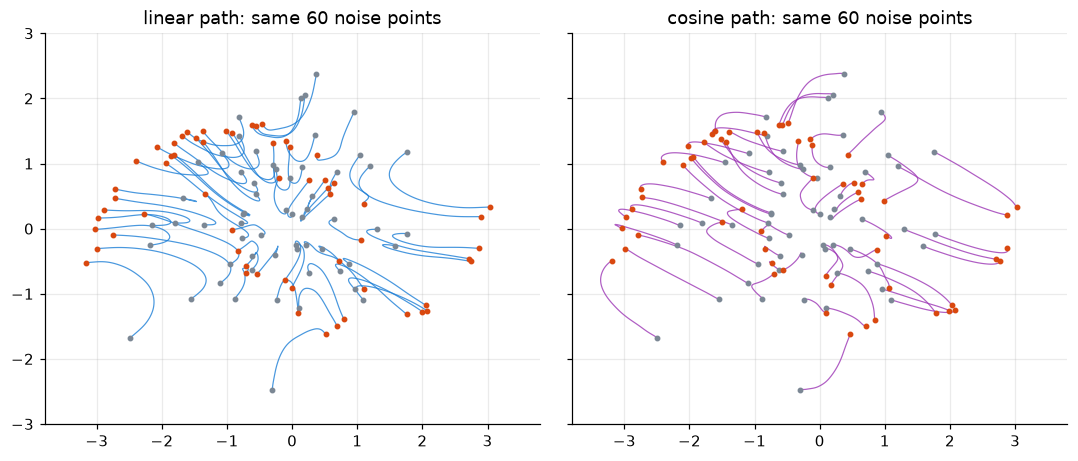

In [9]:
@torch.no_grad()
def straightness(model, z, steps=64, **kw):
    """Mean (path length / chord length) of ODE trajectories; 1.0 = perfectly straight."""
    _, tr = sample(model, z, steps, "heun", return_traj=True, **kw)
    length = (tr[1:] - tr[:-1]).norm(dim=-1).sum(0); chord = (tr[-1] - tr[0]).norm(dim=-1)
    return (length / chord).mean().item()

zs = z0[:2000]
NS = (1, 2, 4, 8, 64)
results = {"linear": [], "cosine": []}
models = {}
for seed in (0, 1, 2):
    for pname in results:
        m = flow if (pname == "linear" and seed == 0) else train_fm(pname, seed=seed, log=False)[0]
        models[(pname, seed)] = m
        results[pname].append(([sliced_w2(sample(m, z0, n, "euler"), ref_a) for n in NS], straightness(m, zs)))
cosine = models[("cosine", 0)]
print(f"{'path':8s} seed " + "".join(f"  N={n:<3d}" for n in NS) + "   straightness")
for pname, rows in results.items():
    for seed, (sw, st) in enumerate(rows): print(f"{pname:8s} {seed:4d} " + "".join(f"  {v:.3f}" for v in sw) + f"      {st:.3f}")

lin_sw4 = [r[0][2] for r in results["linear"]]; cos_sw4 = [r[0][2] for r in results["cosine"]]
lin_st = [r[1] for r in results["linear"]]; cos_st = [r[1] for r in results["cosine"]]
one_step = sample(flow, z0, 1, "euler")
check("[explains the N=1 row] ONE Euler step of the straight-path flow collapses everything onto the data mean",
      one_step.std(0).max() < 0.25 * ref_a.std(0).min(), f"spread of 1-step samples {one_step.std(0).numpy().round(2)} vs data {ref_a.std(0).numpy().round(2)}")
check("[negative result] in this 2-D toy the cosine path is NOT worse at few steps (N=4, 3 of 3 seeds)",
      all(c < l for c, l in zip(cos_sw4, lin_sw4)), f"SW(N=4) cosine {np.round(cos_sw4, 3)} vs linear {np.round(lin_sw4, 3)}")
check("[negative result] the LEARNED straight-path flow is not straight before reflow (path/chord > 1.3)",
      min(lin_st) > 1.3, f"linear {np.round(lin_st, 2)}  cosine {np.round(cos_st, 2)}")
check("with many steps both paths reach the data (within 0.05 of the floor, all seeds)",
      all(r[0][4] < FLOOR + 0.05 for rs in results.values() for r in rs), f"N=64 SW linear {[round(r[0][4], 3) for r in results['linear']]} cosine {[round(r[0][4], 3) for r in results['cosine']]}")

fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for a, m, c, ttl in ((axs[0], flow, FLOW_C, "linear path"), (axs[1], cosine, COS_C, "cosine path")):
    _, tr = sample(m, zs[:60], 64, "heun", return_traj=True)
    for j in range(60): a.plot(tr[:, j, 0], tr[:, j, 1], c=c, lw=.8, alpha=.8)
    a.scatter(*tr[0].T, s=8, c=NOISE_C, zorder=3); a.scatter(*tr[-1].T, s=8, c=DATA_C, zorder=3)
    a.set_title(f"{ttl}: same 60 noise points"); a.set_aspect("equal"); a.set_xlim(-3.8, 3.8); a.set_ylim(-3, 3)
plt.tight_layout(); plt.show()

**The honest reading (this contradicts the simple story).**

- **The "straight path => fewer steps" prediction is *not* reproduced in this toy.** The cosine path gave better few-step Euler samples in all 3 seeds, and its learned trajectories are *straighter*, not more curved.
- **Why the N=1 row is so bad for the straight path:** the first step uses the velocity at $t=0$, which is the *average* arrow $\mathbb E[x_1]-x_0\approx -x_0$. One Euler step therefore lands every point on the data mean - a tiny blob (the check above measures its spread), which scores *worse than raw noise*. The cosine path's field is ~0 at $t=0$ (its target depends on $x_1$ only there), so its first step barely moves the noise - bad, but not a collapse.
- **"Straight conditional paths" is not "straight learned flow".** The *training targets* are straight lines, but the lines cross; the learned marginal flow bends around the crossings (Step 3). Straightness ~1.6 above is exactly that bend - and exactly what **reflow** (next step) removes.
- **What the papers actually claim** is for high-dimensional images (ImageNet, CIFAR). A 2-D, two-mode toy does not have the geometry where the OT path's advantage shows up, so treat this as a caution against over-generalising a slogan - not as evidence against the papers. With 64+ steps both paths work, which is why diffusion models work too: they simply pay more steps.

## Step 8 - Straighter still: *reflow* -> one-step generation

Even the straight-line **training targets** cross; the *learned flow* un-crosses them by "rewiring" - and that is why Step 7 measured a bent flow (path/chord about 1.6). Liu et al. exploit that: after training, run the flow to get pairs $(x_0,\,x_1'=\mathrm{ODE}(x_0))$ - noise points matched to the sample they actually land on. **These pairs do not cross**, so a second model trained on them (initialised from the first) learns almost straight paths.

![Rectified flow Fig. 2](../../assets/flow_matching/rectflow_fig2_reflow.png)

**Liu et al., Fig. 2 (PDF p. 4):** "(a) Linear interpolation of data input $(X_0,X_1)\sim\pi_0\times\pi_1$. (b) The rectified flow $Z_t$ induced by $(X_0,X_1)$; the trajectories are 'rewired' at the intersection points to avoid the crossing. (c) The linear interpolation of the end points $(Z_0,Z_1)$ of flow $Z_t$. (d) The rectified flow induced from $(Z_0,Z_1)$, which follows straight paths."

[linear] 3000 steps in 2s, loss 0.136 -> 0.001
1st flow      SW at N=1/2/4: 1.327  0.665  0.319   straightness 1.632


after reflow  SW at N=1/2/4: 0.062  0.054  0.053   straightness 1.002
PASS - reflow makes the flow straighter | 1.632 -> 1.002
PASS - reflow improves ONE-step generation | SW(N=1) 1.327 -> 0.062


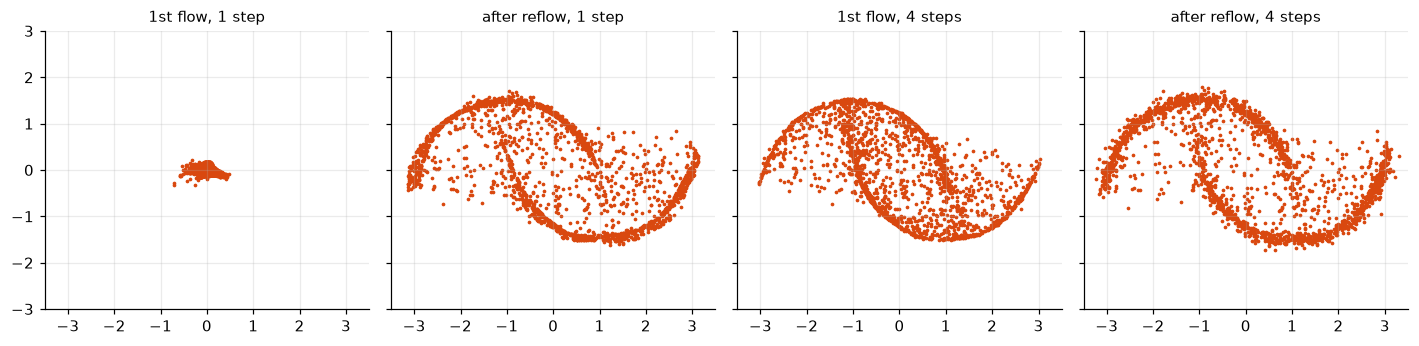

saved /Users/naveenkumarbasaanitha/Music/HaloDiffusionLLM/assets/flow_matching/three_flows.gif (165 KB)


In [10]:
# build the reflow pairs with the trained flow (a fixed pool of noise, matched to where the flow sends it)
torch.manual_seed(3)
pool_x0 = torch.randn(40000, 2)
pool_x1 = torch.cat([sample(flow, pool_x0[i:i + 8000], 64, "heun") for i in range(0, 40000, 8000)])
def reflow_pairs(batch):
    i = torch.randint(0, pool_x0.shape[0], (batch,)); return pool_x0[i], pool_x1[i], torch.zeros(batch, dtype=torch.long)

flow2, _ = train_fm("linear", steps=3000, pair_fn=reflow_pairs, init=flow, lr=1e-3, seed=4)
res = {}
for name, m in (("1st flow", flow), ("after reflow", flow2)):
    res[name] = ([sliced_w2(sample(m, z0, n, "euler"), ref_a) for n in (1, 2, 4)], straightness(m, zs))
    print(f"{name:13s} SW at N=1/2/4: " + "  ".join(f"{v:.3f}" for v in res[name][0]) + f"   straightness {res[name][1]:.3f}")
check("reflow makes the flow straighter", res["after reflow"][1] < res["1st flow"][1], f"{res['1st flow'][1]:.3f} -> {res['after reflow'][1]:.3f}")
check("reflow improves ONE-step generation", res["after reflow"][0][0] < res["1st flow"][0][0], f"SW(N=1) {res['1st flow'][0][0]:.3f} -> {res['after reflow'][0][0]:.3f}")

fig, axs = plt.subplots(1, 4, figsize=(13, 3.3), sharex=True, sharey=True)
for a, (m, n, ttl) in zip(axs, ((flow, 1, "1st flow, 1 step"), (flow2, 1, "after reflow, 1 step"), (flow, 4, "1st flow, 4 steps"), (flow2, 4, "after reflow, 4 steps"))):
    s = sample(m, z0[:2000], n, "euler"); a.scatter(*s.T, s=2, c=DATA_C); a.set_title(ttl, fontsize=10); a.set_aspect("equal"); a.set_xlim(-3.5, 3.5); a.set_ylim(-3, 3)
plt.tight_layout(); plt.show()

@torch.no_grad()
def three_flows_gif(models_titles, path_out, n=36, steps=40, seed=9):
    z = torch.randn(n, 2, generator=torch.Generator().manual_seed(seed))
    trajs = [sample(m, z, steps, "heun", return_traj=True)[1] for m, _, _ in models_titles]
    frames = []
    for k in list(range(0, steps + 1, 2)) + [steps] * 6:
        fig, axs = plt.subplots(1, len(models_titles), figsize=(11, 3.7), sharex=True, sharey=True)
        for a, tr, (_, ttl, c) in zip(axs, trajs, models_titles):
            for j in range(n): a.plot(tr[:k + 1, j, 0], tr[:k + 1, j, 1], c=c, lw=.9, alpha=.8)
            a.scatter(*tr[0].T, s=7, c=NOISE_C, zorder=3); a.scatter(*tr[k].T, s=14, c=DATA_C if k == steps else "k", zorder=4)
            a.set_title(ttl, fontsize=10); a.set_aspect("equal"); a.set_xlim(-3.6, 3.6); a.set_ylim(-3, 3); a.set_xticks([]); a.set_yticks([]); a.grid(False)
        fig.suptitle(f"same 36 noise points, three flows    t = {k/steps:.2f}", fontsize=10); fig.tight_layout()
        frames.append(fig_to_pil(fig)); plt.close(fig)
    frames[0].save(path_out, save_all=True, append_images=frames[1:], duration=90, loop=0, optimize=True)

three_flows_gif([(flow, "1st flow (linear path)", FLOW_C), (cosine, "cosine path (diffusion-style)", COS_C), (flow2, "after reflow", "#2b8a3e")], ASSETS / "three_flows.gif")
print("saved", ASSETS / "three_flows.gif", f"({(ASSETS/'three_flows.gif').stat().st_size//1024} KB)")

![three flows](../../assets/flow_matching/three_flows.gif)

*What to look for:* the **green** (reflowed) trails are near-straight lines from grey start to orange end; the blue ones (straight-path flow) bend and pass through the middle; the purple ones (cosine path) curve gently.

**Read it.** Reflow turns a model that needed many steps into one that is usable in a *single* step - the basis of the fast "distilled" flow models. The honest trade-off: pairs come from the model's own samples, so any error in the first flow is baked in.

## Step 9 - Conditioning and classifier-free guidance

To generate a *particular* moon we feed a class label $y$ into the network. **Classifier-free guidance** (CFG) trains one network for both cases by randomly replacing $y$ with a "no label" token (15 % of the time), then at sampling time *extrapolates* from the unconditional toward the conditional velocity:

$$\tilde v = v_\theta(x,t,\varnothing) + w\,\big(v_\theta(x,t,y)-v_\theta(x,t,\varnothing)\big).$$

$w=0$ ignores the label, $w=1$ is plain conditional sampling, $w>1$ pushes harder toward the class. To make guidance matter we use **noisier moons** (noise 0.3) whose classes overlap, and measure **class accuracy** (15-nearest-neighbour vote against labelled data) and **diversity** (the horizontal spread of one class's samples, relative to the real data's).

[linear cond] 5000 steps in 4s, loss 2.557 -> 1.887
   w  class acc  spread / real


 0.0      0.503           1.19


 1.0      0.905           0.99


 2.0      0.997           0.88


 4.0      1.000           0.65
PASS - w=0 ignores the label (accuracy near chance, 0.5 +- 0.1) | accuracy 0.503
PASS - plain conditional sampling (w=1) beats chance clearly | accuracy 0.905
PASS - guidance raises class accuracy (w=2 > w=1) | 0.905 -> 0.997
PASS - ...at the price of diversity (spread falls from w=1 to w=4) | spread / real: 0.99 -> 0.65


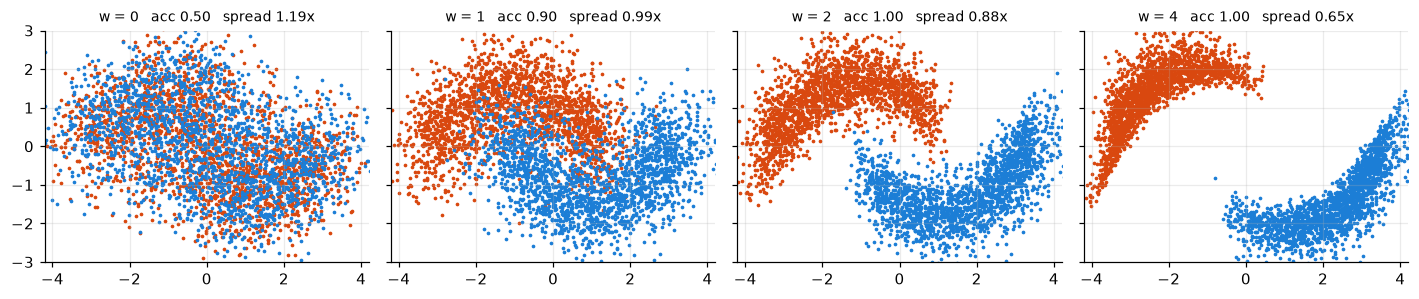

In [11]:
NZ = 0.3                                              # overlapping moons: classes are no longer trivially separable
def noisy_pairs(batch):
    x1, y = moons(batch, noise=NZ); return torch.randn(batch, 2), x1, y

cflow, _ = train_fm("linear", cond=True, steps=5000, seed=6, pair_fn=noisy_pairs)
knn_x, knn_y = moons(6000, noise=NZ, gen=torch.Generator().manual_seed(31))
def classify(pts):
    idx = torch.cdist(pts, knn_x).topk(15, largest=False).indices
    return (knn_y[idx].float().mean(1) > 0.5).long()

yq = torch.arange(4000) % 2
zq = torch.randn(4000, 2, generator=torch.Generator().manual_seed(41))
real_spread = knn_x[knn_y == 0, 0].std().item()
res = []
print(f"{'w':>4s}  {'class acc':>9s}  {'spread / real':>13s}")
for w in (0.0, 1.0, 2.0, 4.0):
    s = sample(cflow, zq, 64, "heun", y=yq, w=w)
    acc = (classify(s) == yq).float().mean().item()
    spread = s[yq == 0, 0].std().item() / real_spread
    res.append((w, acc, spread, s)); print(f"{w:4.1f}  {acc:9.3f}  {spread:13.2f}")
check("w=0 ignores the label (accuracy near chance, 0.5 +- 0.1)", abs(res[0][1] - 0.5) < 0.1, f"accuracy {res[0][1]:.3f}")
check("plain conditional sampling (w=1) beats chance clearly", res[1][1] > 0.85, f"accuracy {res[1][1]:.3f}")
check("guidance raises class accuracy (w=2 > w=1)", res[2][1] > res[1][1], f"{res[1][1]:.3f} -> {res[2][1]:.3f}")
check("...at the price of diversity (spread falls from w=1 to w=4)", res[3][2] < res[1][2], f"spread / real: {res[1][2]:.2f} -> {res[3][2]:.2f}")

fig, axs = plt.subplots(1, 4, figsize=(13, 3.2), sharex=True, sharey=True)
for a, (w, acc, spread, s) in zip(axs, res):
    a.scatter(*s[yq == 0].T, s=2, c=DATA_C); a.scatter(*s[yq == 1].T, s=2, c=FLOW_C)
    a.set_title(f"w = {w:g}   acc {acc:.2f}   spread {spread:.2f}x", fontsize=9); a.set_aspect("equal"); a.set_xlim(-4.2, 4.2); a.set_ylim(-3, 3)
plt.tight_layout(); plt.show()

**Read it.** $w=0$ draws from the *unconditional* mixture (orange and blue mixed, accuracy at chance); $w=1$ respects the label but the overlap still costs accuracy; larger $w$ separates the classes (accuracy up) while each class **shrinks toward its core** - the fidelity-vs-diversity dial of guidance, visible in 2-D.

## Step 10 - Where this shows up (this repo, and driving)

**Discrete flow matching for text (this repo, `variant: flow_matching`).** Text tokens cannot be nudged by a velocity, so the same *recipe* is applied to a **masking path**: at time $t$ each token is still masked with probability `mask_prob(t) = 1 - t`; the model predicts the clean token, and the loss is weighted by `1 / mask_prob(t)` (the "rate"). The code below is read straight from the repo files (not re-implemented):

In [12]:
repo = Path("../..").resolve() / "src" / "hale_llm" / "models" / "models_flow_matching"
src = (repo / "vector_field.py").read_text(); lossf = (repo / "loss.py").read_text()
print("# vector_field.py (the path)")
print("def mask_prob(t):", "return 1.0 - t" if "return 1.0 - t" in src else "<changed!>")
print("\n# loss.py (the whole training objective)")
print("@register_loss" + lossf.split("@register_loss")[1])
check("repo's masking path is the linear 1 - t (the discrete twin of the straight path)", "return 1.0 - t" in src)
check("repo's loss weights masked-token NLL by 1 / mask_prob(t)", "1.0 / mask_prob(t)" in lossf)

# vector_field.py (the path)
def mask_prob(t): return 1.0 - t

# loss.py (the whole training objective)
@register_loss("flow_matching")
def flow_matching_loss(model, batch: dict) -> torch.Tensor:
    """Masked-token NLL weighted by ``1 / mask_prob(t)`` on the linear path at a random ``t``."""
    x1 = batch["input_ids"]
    batch_size, seq_len = x1.shape
    device = x1.device
    t = torch.rand(batch_size, device=device) * (1.0 - model.eps)
    keep_mask = mask_prob(t).clamp(0, 1)[:, None].expand(batch_size, seq_len)
    is_masked = torch.rand(batch_size, seq_len, device=device) < keep_mask
    x_t = torch.where(is_masked, torch.full_like(x1, batch["mask_token_id"]), x1)
    logits = model({**batch, "x_t": x_t, "t": t})
    loss_pos = is_masked
    if batch.get("attention_mask") is not None:
        loss_pos = loss_pos & batch["attention_mask"].bool()
    nll = model_token_nll(model, logits, x1, reduction="none")
    weight = (1.0 / mask_prob(t).clamp(min=model.eps))[:, None]
    retu

| | continuous (this notebook) | discrete text (`models_flow_matching`) |
|---|---|---|
| state | position $x\in\mathbb R^2$ | token sequence (some masked) |
| path | $x_t=(1-t)x_0+t\,x_1$ | mask each token w.p. $1-t$ |
| network predicts | velocity $x_1-x_0$ | the clean token |
| sampling | ODE steps | unmask tokens step by step |

**Driving and robotics.** Flow matching is also how many action heads produce *continuous trajectories*: the Alpamayo-R1 paper (`assets/lifting_papers/alpamayo_fig1.png` in `Halos-lift`) states that *"an action-expert decoder using flow matching converts the discrete trajectory tokens into continuous, kinematically feasible waypoints conditioned on the reasoning output"* - the same velocity regression as above, with the waypoints as $x_1$ and the scene context as the condition.

In [13]:
print(f"{'#':>2s}  {'status':6s}  check")
for i, (n, ok, d) in enumerate(CHECKS, 1): print(f"{i:2d}  {'PASS' if ok else 'FAIL':6s}  {n}")
failed = [n for n, ok, _ in CHECKS if not ok]
print(f"\n{len(CHECKS) - len(failed)} passed, {len(failed)} failed")
assert not failed, failed

 #  status  check
 1  PASS    path starts at the noise point (t=0)
 2  PASS    path ends at the data point (t=1)
 3  PASS    finite-difference d x_t / dt equals x1 - x0
 4  PASS    binned pair-velocities match the closed form at t=0.3
 5  PASS    binned pair-velocities match the closed form at t=0.6
 6  PASS    the CFM-trained network recovers the exact marginal velocity
 7  PASS    more Euler steps -> better samples (N=1 is much worse than N=64)
 8  PASS    with enough steps the samples reach the data-vs-data floor (within 0.05)
 9  PASS    Heun beats Euler at the same NFE (8 calls)
10  PASS    [explains the N=1 row] ONE Euler step of the straight-path flow collapses everything onto the data mean
11  PASS    [negative result] in this 2-D toy the cosine path is NOT worse at few steps (N=4, 3 of 3 seeds)
12  PASS    [negative result] the LEARNED straight-path flow is not straight before reflow (path/chord > 1.3)
13  PASS    with many steps both paths reach the data (within 0.05 of the f

## Takeaways

1. **Generation = transport.** A network outputs a velocity; sampling integrates an ODE from noise to data.
2. **Training is plain regression**: pick a path (straight), compute its constant velocity $x_1-x_0$, minimise a squared error (Eq. 9). No simulation, no noise schedule to tune. The optimum is the *average* pair-velocity - verified against a closed form in Step 4.
3. **Straight *targets* do not make a straight *flow*.** In this toy the straight-path flow was bent (and the cosine path was not worse at few steps) - Step 7. **Reflow** is what straightens it and enables one-step sampling (Step 8). Diffusion is the same machinery with another path.
4. **CFG** works unchanged: one network, label dropout, extrapolate at sampling time.
5. The same recipe carries over to **discrete tokens** (masking path - this repo) and to **action trajectories**.

### Exercises
- Replace the two moons by a 3-spiral set; how many Euler steps are needed now?
- Make the source a *different* distribution (e.g. a ring) instead of Gaussian noise: nothing in the loss requires $x_0$ to be Gaussian (domain transfer, Liu et al.).
- Try `p_uncond=0` in Step 9 and see why guidance needs the "no label" token.
- Add a third path, e.g. $x_t=(1-t^2)x_0+t^2x_1$, and compare its straightness.

### Honest limits
2-D toy data, small MLPs and single seeds: the *trends* (reflow straightening, guidance trading diversity for accuracy, step-count/quality curves) are measured above, as is one that went *against* the usual slogan (Step 7), but the absolute numbers will move with seeds and sizes. Large-scale claims are the papers', not tested here.